In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
import os

# Data Ingest

In [157]:
def get_data(path, total_channels):

    start_time_line = 7
    measurement_time_line = 9
    data_start_line = 12
    data_end_line = 12 + total_channels


    in_file = open(path, "r")

    lines = in_file.readlines()

    start = lines[start_time_line].strip().split(" ")
    start_date, start_time = start[0], start[1]

    measurement_time = lines[measurement_time_line].strip().split(" ")
    live_time, real_time  = measurement_time[0], measurement_time[1]

    data = lines[data_start_line:data_end_line + 1]

    data_dict = {
        "start_date": start_date,
        "start_time": start_time,
        "live_time": float(live_time),
        "real_time": float(real_time),
        "dead_time": float(np.divide(np.subtract(float(real_time),float(live_time)),float(real_time)) * 100),
        "data": [int(x.strip()) for x in data]
    }

    in_file.close()

    return data_dict


# Data Paths and Global Variables

In [158]:
mu = "\u03bc"

TOTAL_CHANNELS = 8192 - 1
TOTAL_CHANNELS_2 = 512-1

# T_DELAY_US = 0.28
T_DELAY_US = 0.800

data_folder_path = r"G:\My Drive\ADVLAB\Muon-Lifetime\Data"

# data_path = data_folder_path + r"/MuonTest.Spe"
# data_path = data_folder_path + r"/MuonTest2.Spe"
# data_path = data_folder_path + r"/MuonTest3.Spe"
# data_path = data_folder_path + r"/MuonTest4.Spe"
# data_path = data_folder_path + r"/MuonTest6.1.Spe"
data_path = data_folder_path + r"/MuonTest6.2.Spe"

time_cal_path_1 = data_folder_path + r"/timeCal_P0128_R2048.Spe"
time_cal_path_2 = data_folder_path + r"/timeCal512_P0128_P2048.Spe"

hourly_folder_path = data_folder_path + r"/MuonCounts"



# Data Rebinning

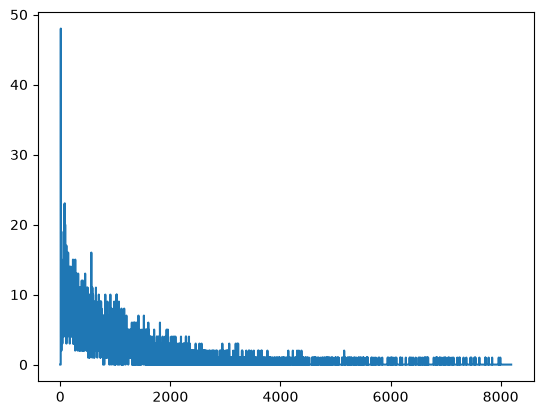

In [159]:
data_dict = get_data(data_path, TOTAL_CHANNELS)
plt.plot(data_dict["data"])
plt.show()

In [160]:
# Bin counts the caller can choose from (2**9 ... 2**14).
ALLOWED_BINS = (512, 1024, 2048, 4096, 8192, 16384)

def rebin_histogram(counts, n_bins):
    """
    Rebin a histogram to `n_bins` channels, conserving the total counts.
    """
    counts = np.asarray(counts)

    n_bins = int(n_bins)

    n_in = counts.size  # number of channels in the given data

    if n_in % n_bins == 0:
        # Whole number of old channels per new bin: sum each block.
        return counts.reshape(n_bins, n_in // n_bins).sum(axis=1)

    # General case: treat each channel's counts as spread evenly across it
    # and integrate that over the new bin edges.
    old_edges = np.arange(n_in + 1)
    new_edges = np.linspace(0, n_in, n_bins + 1)
    cumulative = np.concatenate(([0.0], np.cumsum(counts, dtype=float)))
    return np.diff(np.interp(new_edges, old_edges, cumulative))

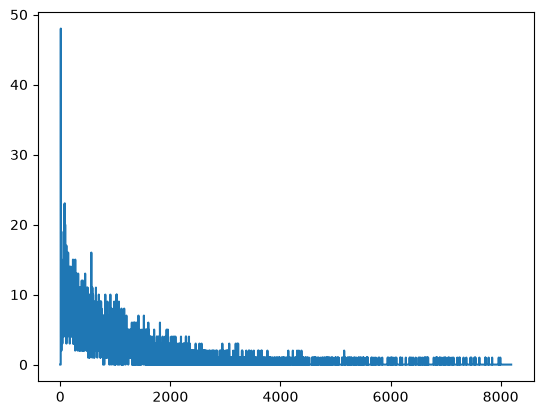

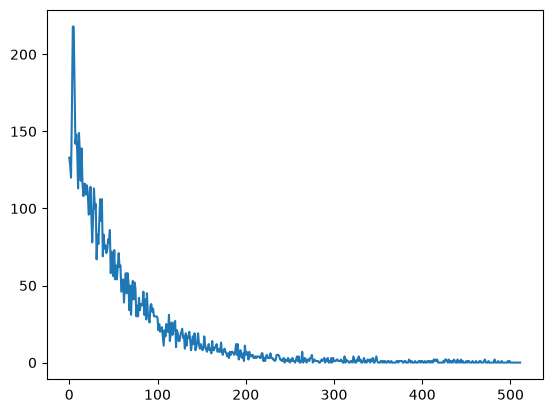

In [161]:
plt.plot(data_dict['data'])
plt.show()

copy_data = data_dict['data'].copy()
rebinned_data = rebin_histogram(copy_data, 512)

rebinned_data_dict = data_dict.copy()
rebinned_data_dict['data'] = rebinned_data

plt.plot(rebinned_data)
plt.show()

# Time Calibration

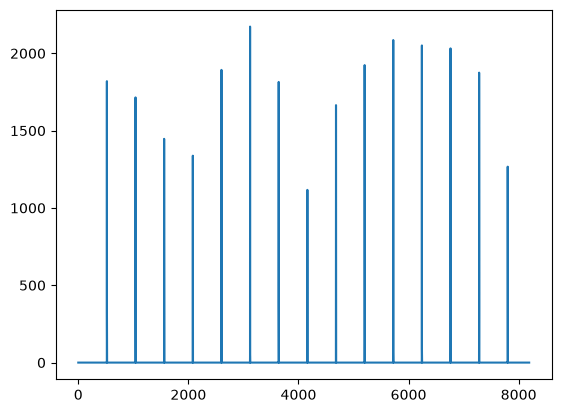

In [162]:
time_cal_1 = get_data(time_cal_path_1, TOTAL_CHANNELS)
plt.plot(time_cal_1["data"])
plt.show()

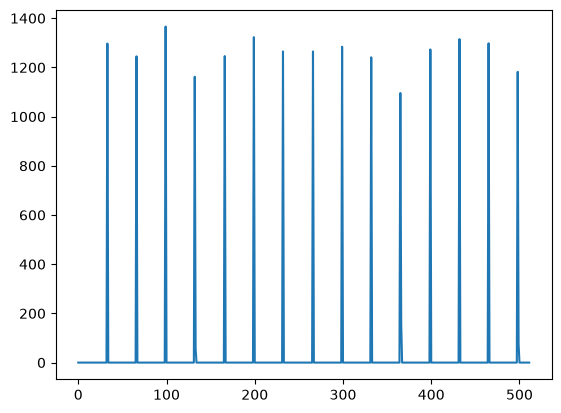

In [163]:
time_cal_2 = get_data(time_cal_path_2, TOTAL_CHANNELS_2)
plt.plot(time_cal_2["data"])
plt.show()

In [164]:
def get_time_cal(data_dict, time_cal_dict, period, degree):

  # convert data and time_cal to numpy arrays
  time_cal = np.array(time_cal_dict["data"])

  # keep only the tallest channel within +-10 channels of each peak
  original = time_cal.copy()   # compare against untouched counts
  for i in range(len(original)):
    if original[i] > 0:
      lo, hi = max(i - 10, 0), min(i + 11, len(original))
      if i != lo + np.argmax(original[lo:hi]):
        time_cal[i] = 0

  # assign 1 to any element that is non zero
  binary_peaks = np.zeros_like(time_cal)
  binary_peaks[time_cal > 0] = 1

  # # the first peak should be 2
  # binary_peaks[np.where(binary_peaks >0 )[0][0]] = 2

  # set each non zero entry to the sum of all before it
  cumulative_peaks = np.cumulative_sum(binary_peaks)
  step_array = cumulative_peaks.astype(np.float64)

  # set regions that are not peaks in raw calibration data to 0.0
  step_array[binary_peaks == 0] = 0.0

  # multiply all nonzero entries by the calibration period
  step_array *= period

  # get just the peaks and their indexes to fit
  peak_indexes = np.where(step_array > 0)[0]
  step_array = step_array[peak_indexes]

  # fit the steps by channel using polyfit
  fit_steps, cov = np.polyfit(peak_indexes, step_array, degree, cov=True)

  # print(np.sqrt(cov[0, 0]))

  return fit_steps, step_array, binary_peaks


In [165]:
def get_time_from_channel_linear(channel, fit_steps):
  return fit_steps[0] * channel + fit_steps[1]

In [166]:
def get_channel_from_time_linear(time, fit_steps):
  return int(np.divide(time - fit_steps[1], fit_steps[0]).round())

In [167]:
def get_time_fit(dict_data, time_cal_dict, show_plot = False):

  time_fit_param, step_array, binary_peaks = get_time_cal(dict_data, time_cal_dict, period = 1.28, degree = 1)
  peak_channels = np.where(binary_peaks > 0)[0]

  time_fit = get_time_from_channel_linear(peak_channels, time_fit_param)

  if show_plot:
    plt.plot(binary_peaks)
    plt.show()

    plt.scatter(peak_channels, step_array, marker = 'o')
    plt.plot(peak_channels, time_fit )
    plt.xlabel("Channel")
    plt.ylabel(f"Time ({mu}s)")
    plt.annotate( f"t = {time_fit_param[0] : .4f} * x - {abs(time_fit_param[1]): .4f}", (max(peak_channels)*.2, 15.5), fontsize=11) # top left annotate the fit equation
    plt.show()

  return time_fit_param

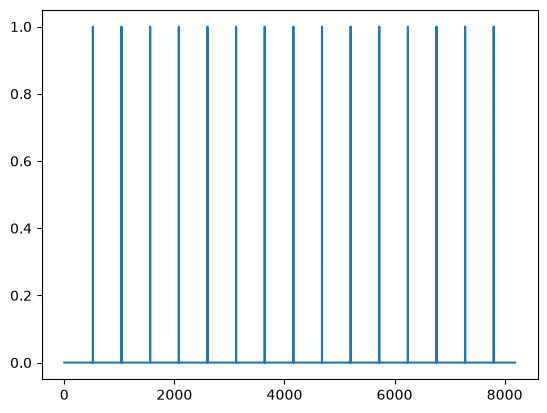

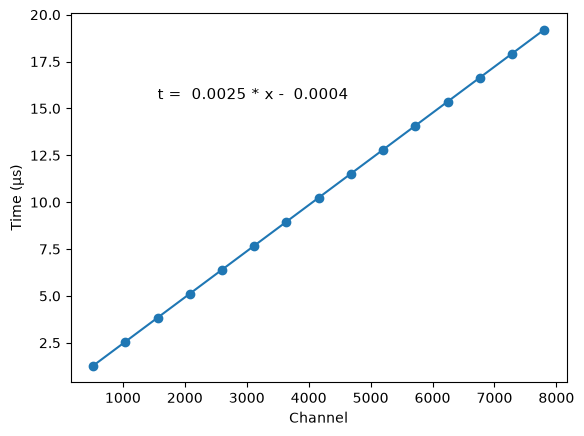

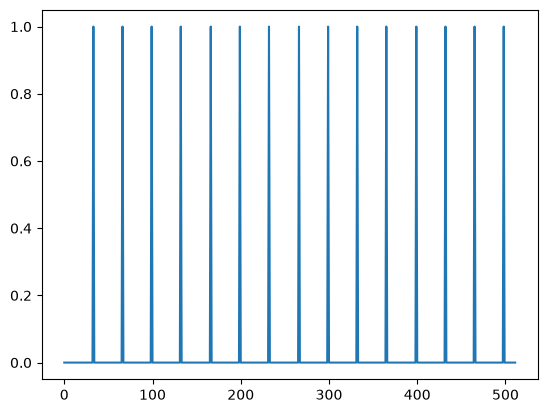

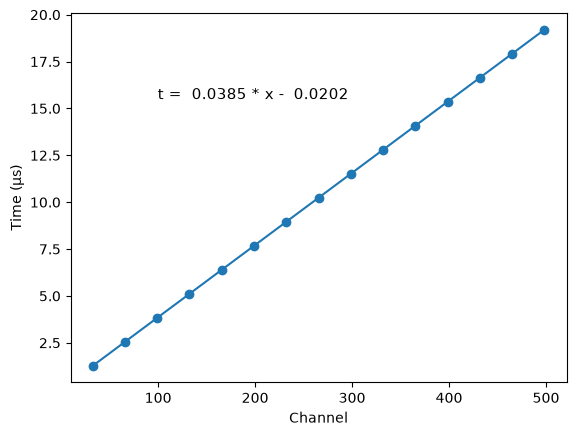

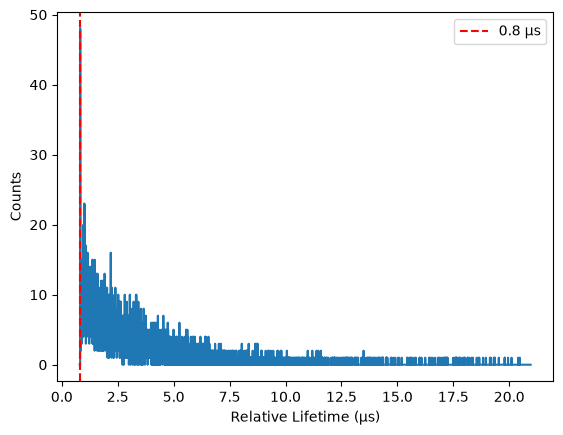

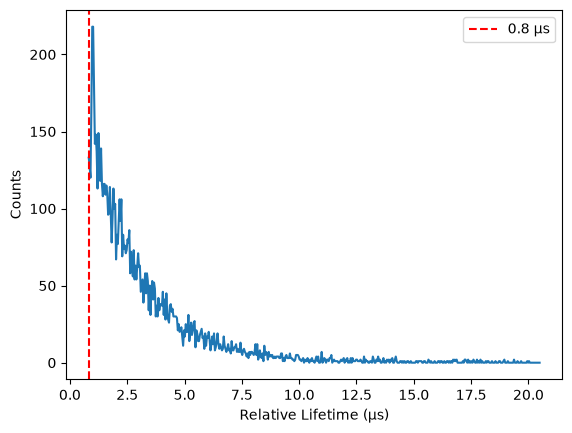

In [ ]:
time_fit_param = get_time_fit(data_dict, time_cal_1, show_plot = True)
time_fit_param_512 = get_time_fit(rebinned_data_dict, time_cal_2, show_plot = True)


# plot the data vs time
channel_range = np.arange(len(data_dict["data"]))
channel_range_512 = np.arange(len(rebinned_data_dict["data"]))

time_range = get_time_from_channel_linear(channel_range, time_fit_param)
time_range_512 = get_time_from_channel_linear(channel_range_512, time_fit_param_512)

time_range_delayed = time_range + T_DELAY_US
time_range_512_delayed = time_range_512 + T_DELAY_US


plt.plot(time_range_delayed, data_dict["data"] )
plt.xlabel(f"Relative Lifetime ({mu}s)")
plt.ylabel("Counts")
plt.axvline(time_range_delayed[0], color='r', linestyle='--', label = f"0.8 {mu}s")
plt.legend()
plt.show()

plt.plot(time_range_512_delayed, rebinned_data_dict["data"] )
plt.xlabel(f"Relative Lifetime ({mu}s)")
plt.ylabel("Counts")
plt.axvline(time_range_512_delayed[0], color='r', linestyle='--', label = f"0.8 {mu}s")
plt.legend()
plt.show()

# Data Fitting

In [169]:
def fit_exp_dist_w_oxy_Si(data, start_channel, end_channel, time_fit_parameters, bw):

        x_data = np.arange(start_channel, end_channel + 1)
        x_time = get_time_from_channel_linear(x_data, time_fit_parameters) + T_DELAY_US
        y_data = data[start_channel: end_channel + 1]

        def exp_func_w_O_Si(t, N_0, tau, C):
                return (N_0 * (np.exp(-t/tau) + .26 * np.exp(-t/1.795) + 0.19*np.exp(-t/0.756)) + C )* bw


        ############## iteratively reweighted least squares (IRLS) ##############

        p0 = [max(y_data[:20].mean(), 1)/bw*np.exp(x_time[0]/2.2),   # rate scaled back to t = 0
                2.2, max(y_data[-200:].mean()/bw, 0.1)]
        lo, hi = [0, 0.5, 0], [np.inf, 5.0, np.inf]              # N_0 ≥ 0, 0.5 < tau < 5, C ≥ 0


        # Step 0: rough weights from the data, just to get a starting point
        p = opt.curve_fit(exp_func_w_O_Si, x_time, y_data, p0=p0, sigma=np.sqrt(np.maximum(y_data, 1)), bounds=(lo, hi))[0]

        # Steps 1+: weights from the model, refit until stable
        for i in range(10):
                sigma = np.sqrt(np.maximum(exp_func_w_O_Si(x_time, *p), 1e-6))  # sqrt of expected counts; floor avoids /0
                p_new, cov = opt.curve_fit(exp_func_w_O_Si, x_time, y_data, p0=p, sigma=sigma, absolute_sigma=True, bounds=(lo, hi))
                err = np.sqrt(np.diag(cov))
                converged = np.all(np.abs(p_new - p) < 1e-4*err)   # change much smaller than the error
                p = p_new
                if converged:
                        break

        fit_N_0, fit_tau, fit_C = p

        tau_err = err[1]
        mu = exp_func_w_O_Si(x_time, *p)

        print(f"tau error: {tau_err}")

        fit_y_data = exp_func_w_O_Si(x_time, fit_N_0, fit_tau,  fit_C)

        redux_chi2 = np.sum((y_data - mu)**2 / mu) / (len(y_data) - 3)

        print(f"reduced chi squared: {redux_chi2}")

        return fit_y_data, fit_N_0, fit_tau , fit_C, tau_err

tau error: 0.03616587992164134
reduced chi squared: 1.063545267740203


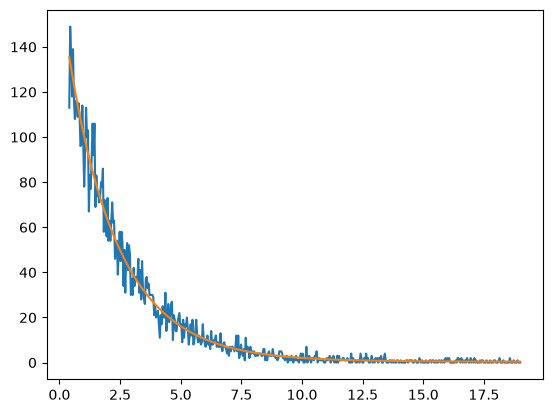

tau error: 0.03683191262406433
reduced chi squared: 1.0560172093369025


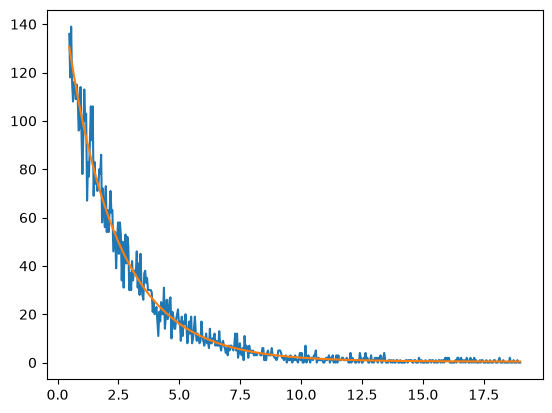

tau error: 0.03803277350244844
reduced chi squared: 1.0576424658842278


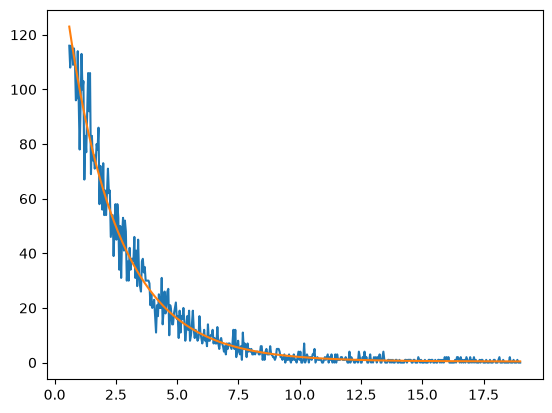

tau error: 0.03895743358650707
reduced chi squared: 1.059893178818069


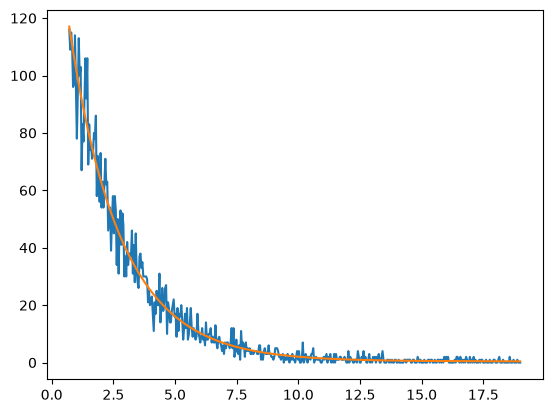

tau error: 0.039676034842472604
reduced chi squared: 1.0635831478896431


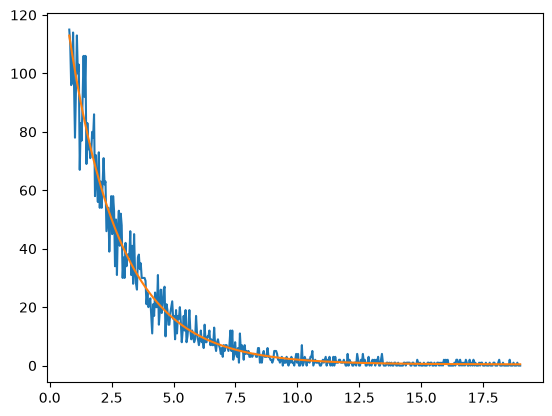

tau error: 0.040764730680336835
reduced chi squared: 1.0667618556884841


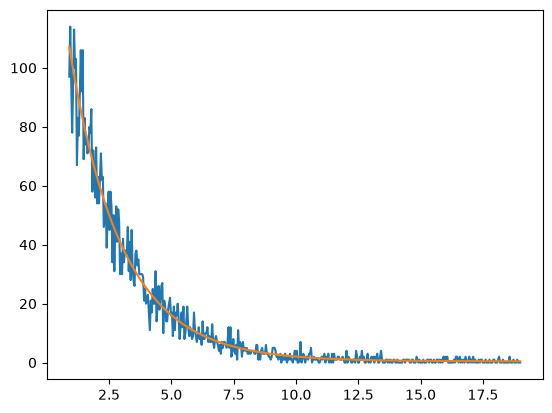

tau error: 0.04158798078585913
reduced chi squared: 1.067650442325415


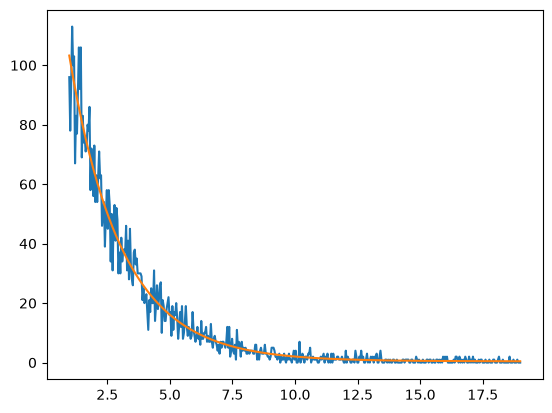

tau error: 0.04238589181551512
reduced chi squared: 1.0592859826170258


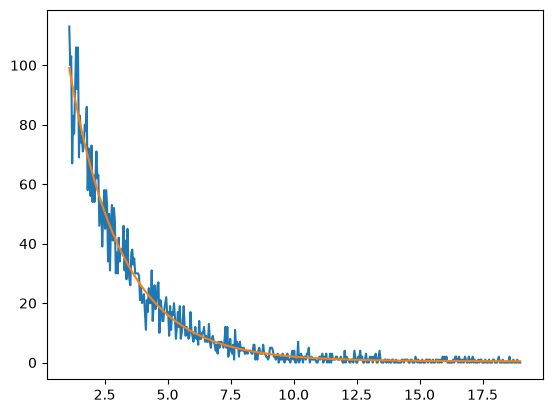

tau error: 0.04410173187205423
reduced chi squared: 1.0604146830870058


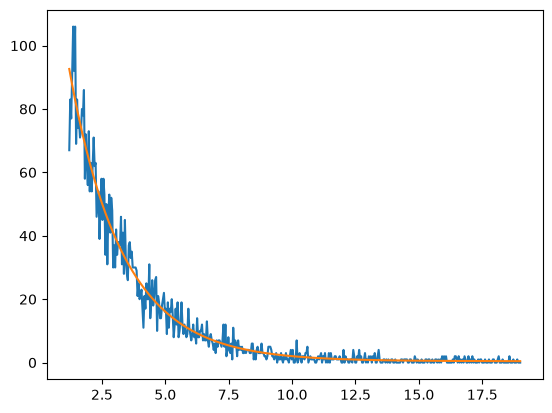

tau error: 0.044486418312369894
reduced chi squared: 1.0463128593356983


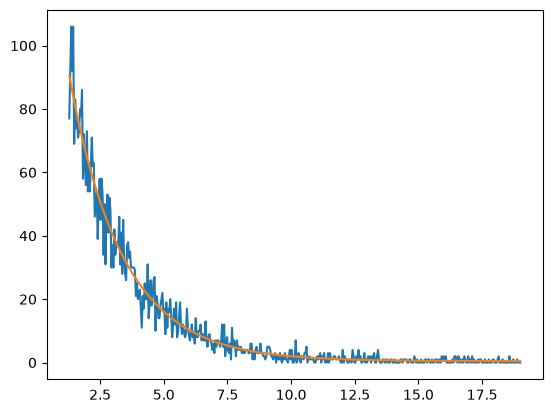

tau error: 0.04604895413727278
reduced chi squared: 1.0397439983407528


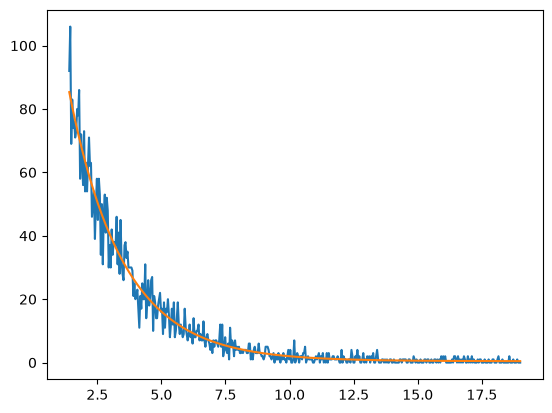

tau error: 0.04757487803016918
reduced chi squared: 1.0295977563274872


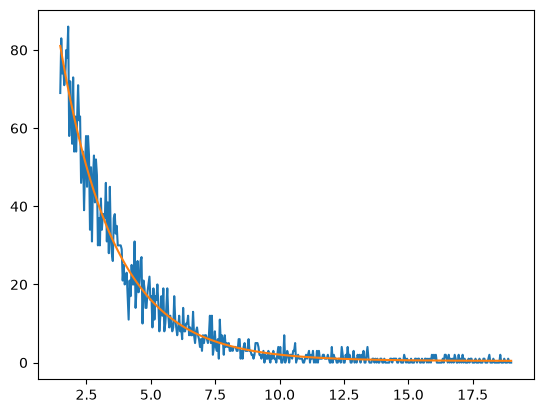

tau error: 0.0488230342908211
reduced chi squared: 1.0312958424606036


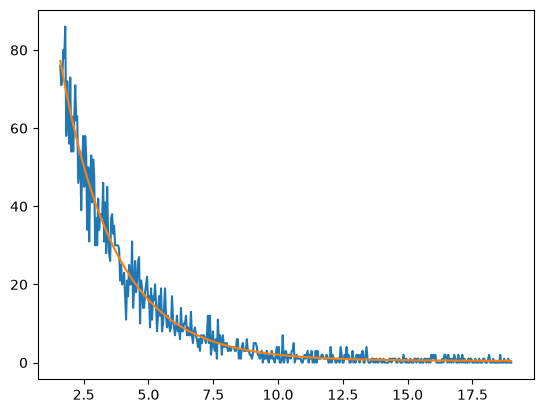

tau error: 0.05022477917186685
reduced chi squared: 1.0372181812859116


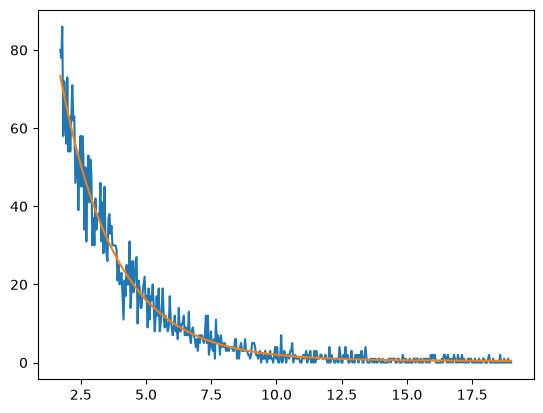

tau error: 0.05161167647030896
reduced chi squared: 1.0394945024417157


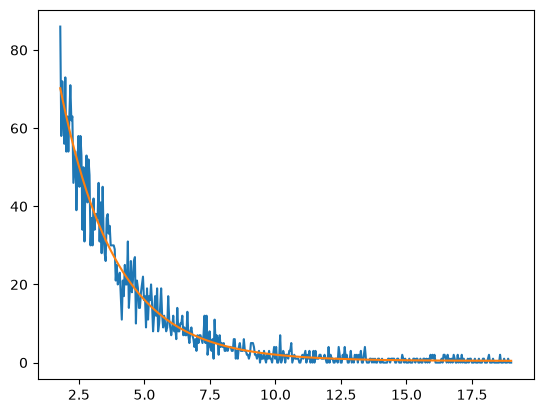

tau error: 0.05353873321025368
reduced chi squared: 1.034023210768688


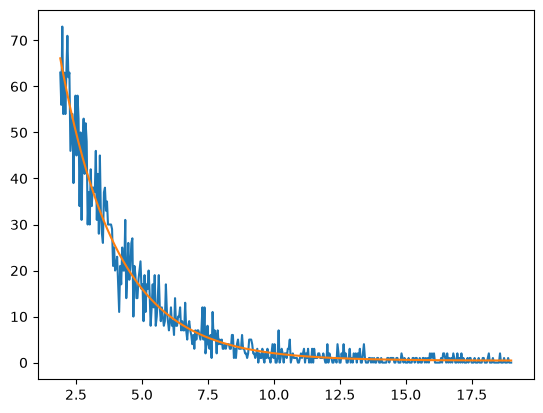

tau error: 0.05434221009891705
reduced chi squared: 1.0351279872680348


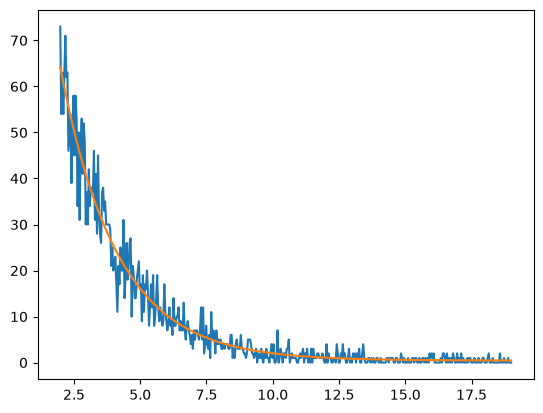

tau error: 0.05614579692626705
reduced chi squared: 1.0364750820441373


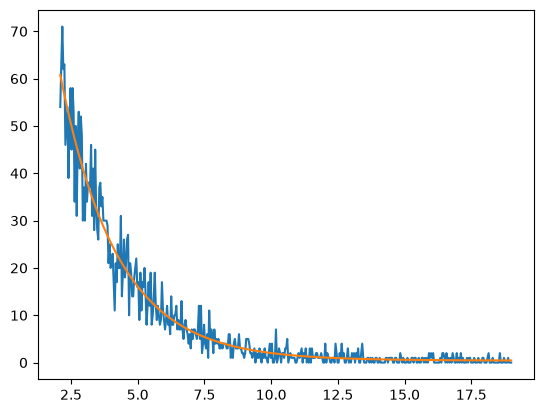

tau error: 0.058295864533683975
reduced chi squared: 1.0355842804824638


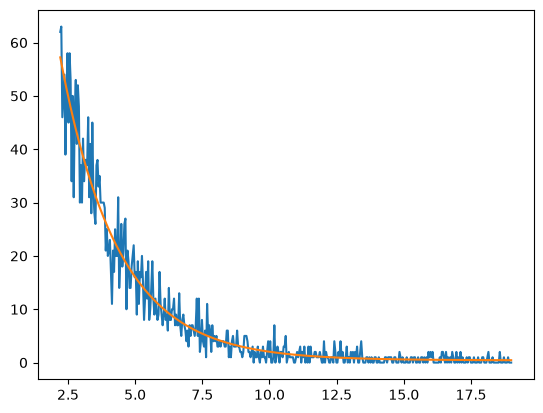

tau error: 0.060008754051430205
reduced chi squared: 1.03766356736956


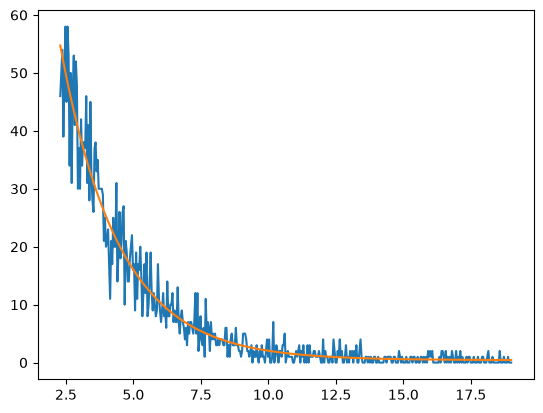

tau error: 0.061494573960725205
reduced chi squared: 1.0403831689200338


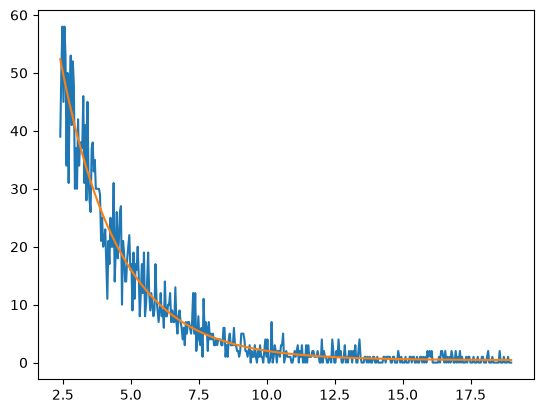

tau error: 0.06219638182569859
reduced chi squared: 1.0362976558674393


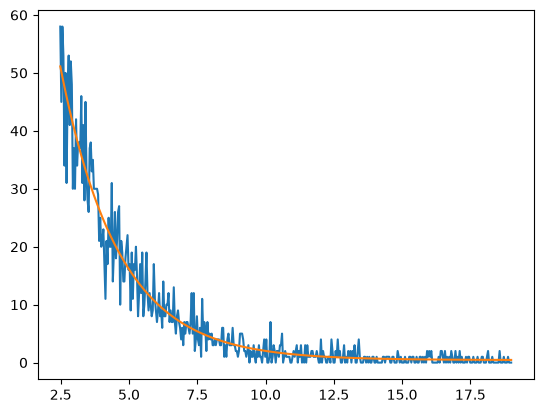

tau error: 0.06478206911035213
reduced chi squared: 1.036692221823345


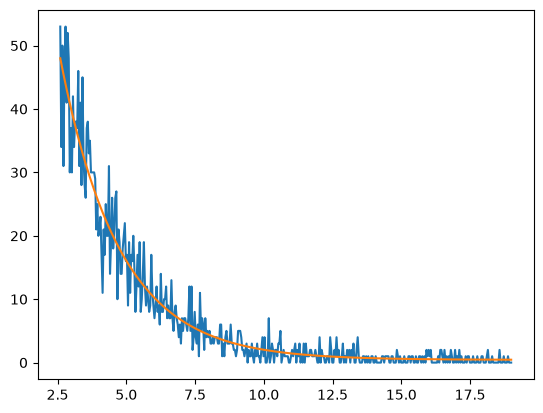

tau error: 0.06671456412889472
reduced chi squared: 1.03324016121995


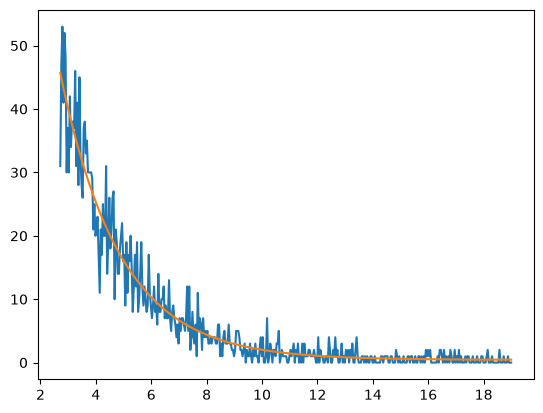

tau error: 0.06749976117961172
reduced chi squared: 1.025958199891054


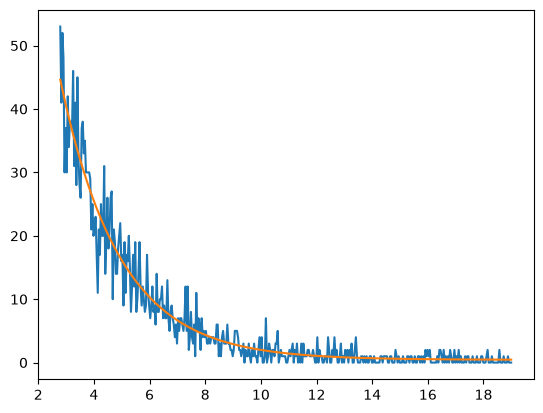

tau error: 0.07071131185845553
reduced chi squared: 1.0245153743815125


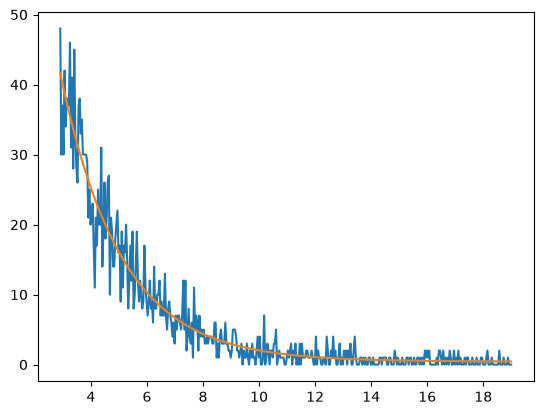

tau error: 0.07200587282098177
reduced chi squared: 1.0199095780400167


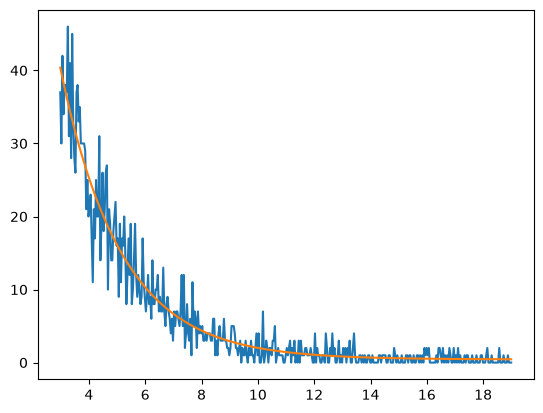

tau error: 0.07373232032323802
reduced chi squared: 1.0198337084975593


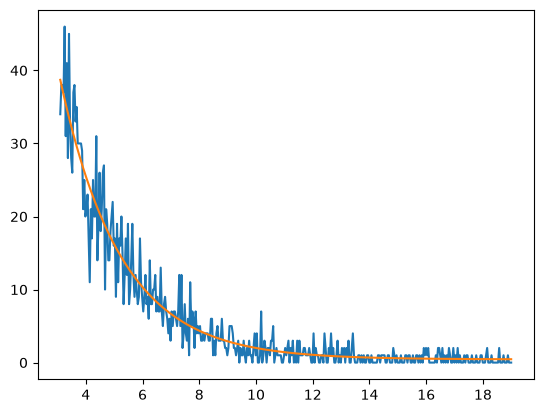

tau error: 0.07595820756110014
reduced chi squared: 1.0257233453284837


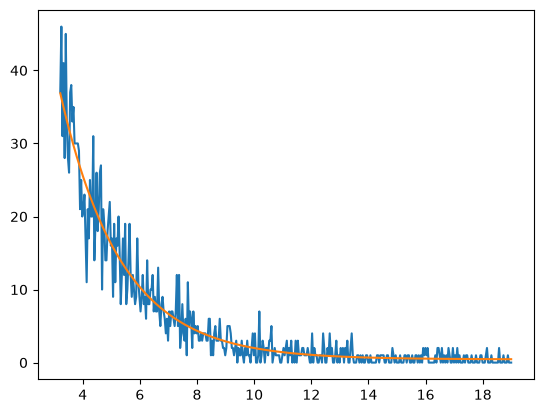

tau error: 0.07855368477477911
reduced chi squared: 1.0243079358549432


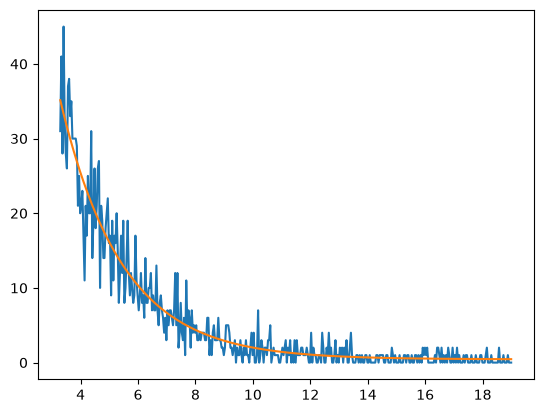

tau error: 0.08094902593131621
reduced chi squared: 1.0249693282288583


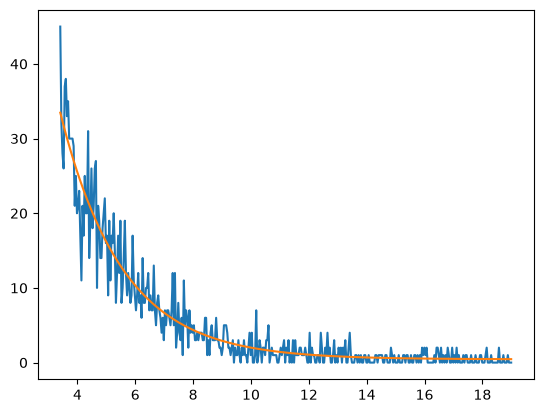

tau error: 0.08394240077851345
reduced chi squared: 1.02006477340027


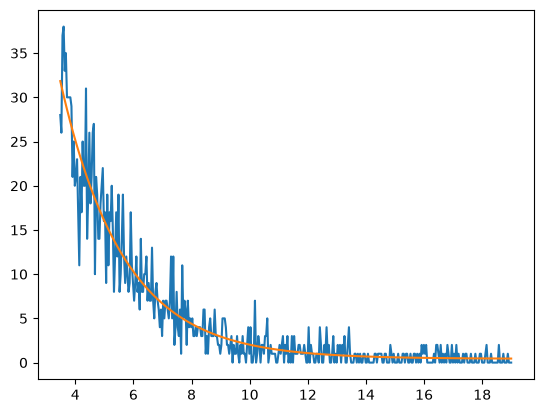

tau error: 0.08652638951930597
reduced chi squared: 1.0210336640276847


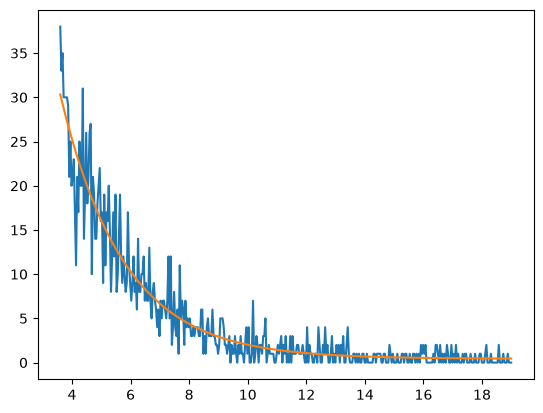

tau error: 0.09180968246037666
reduced chi squared: 1.019695945245406


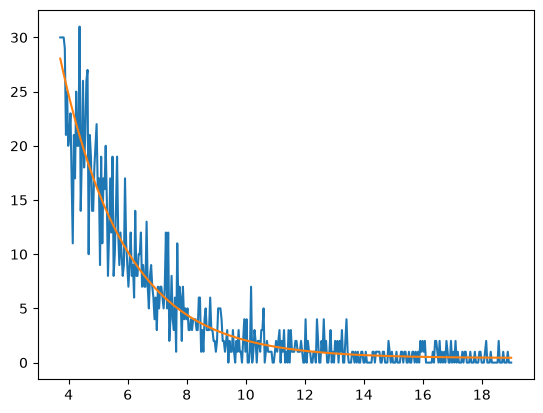

tau error: 0.09459358907692514
reduced chi squared: 1.024128056722431


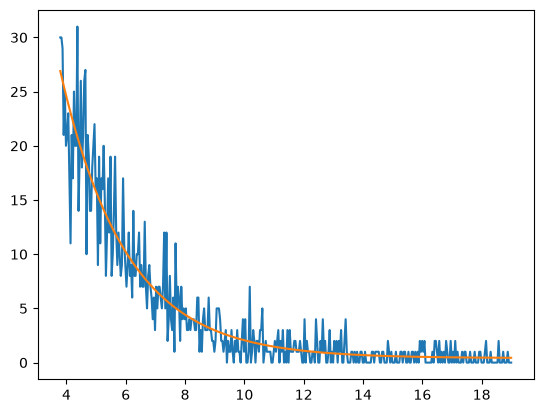

tau error: 0.09957598140519767
reduced chi squared: 1.0291467452027967


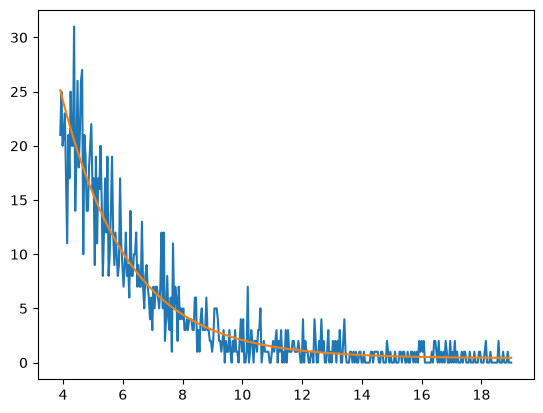

tau error: 0.10115040268527306
reduced chi squared: 1.0323492031932822


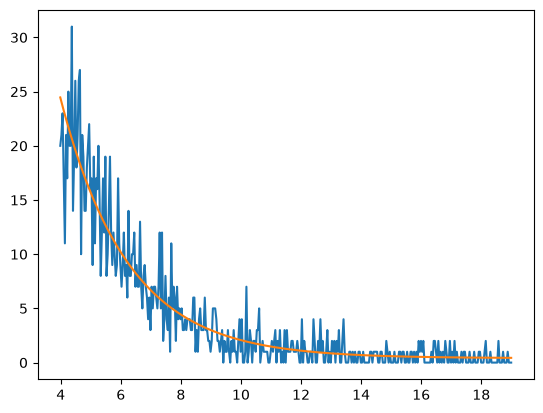

tau error: 0.10304655939241765
reduced chi squared: 1.0362325891321476


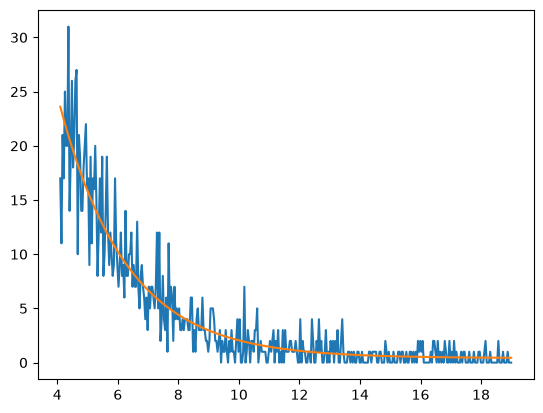

tau error: 0.10247531742782673
reduced chi squared: 1.019072788104162


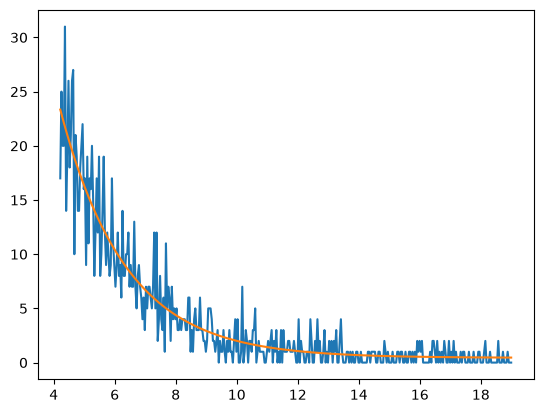

tau error: 0.10408902264920475
reduced chi squared: 1.0191191253959546


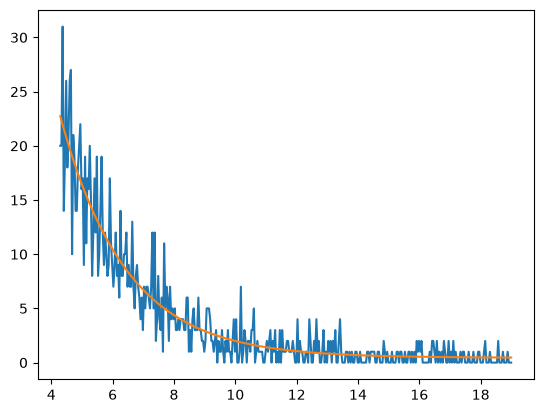

tau error: 0.10880420974947895
reduced chi squared: 1.015909488620779


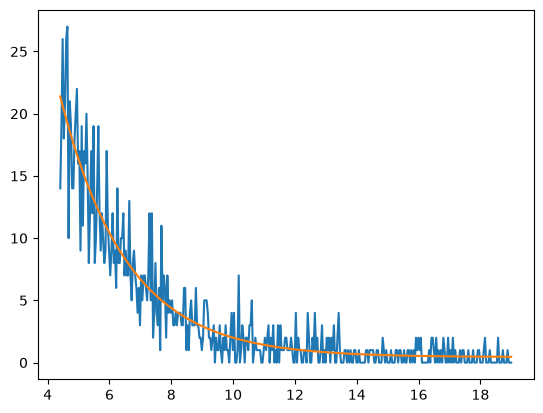

tau error: 0.10925945388670322
reduced chi squared: 1.0131612256640512


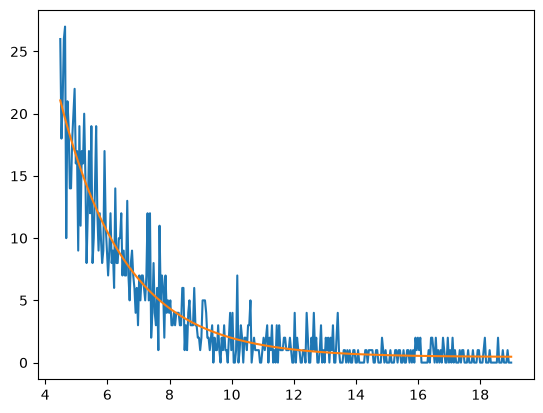

tau error: 0.11414114980634027
reduced chi squared: 1.0172750567598274


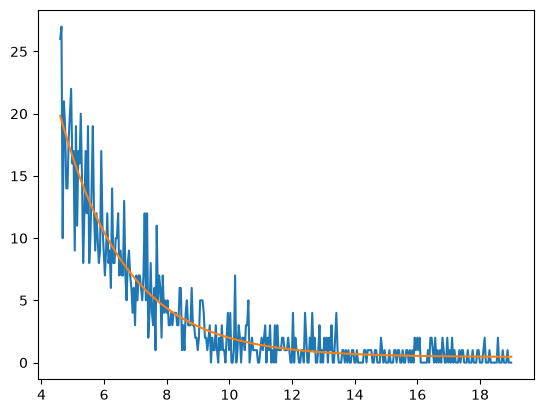

tau error: 0.1198779585727051
reduced chi squared: 1.0004315942240987


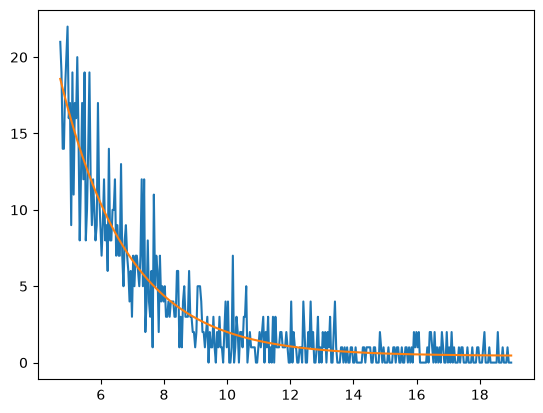

tau error: 0.12392254322237299
reduced chi squared: 1.0049294332764513


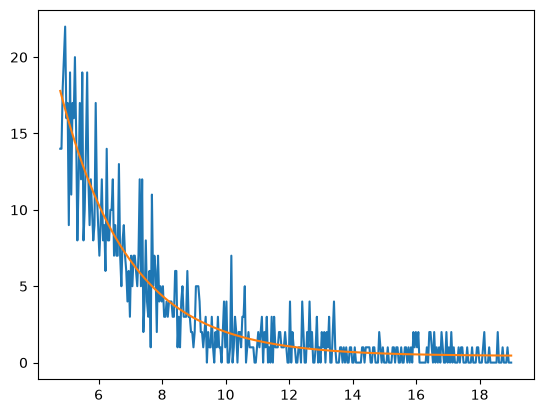

tau error: 0.12621480049608721
reduced chi squared: 1.0085073675300014


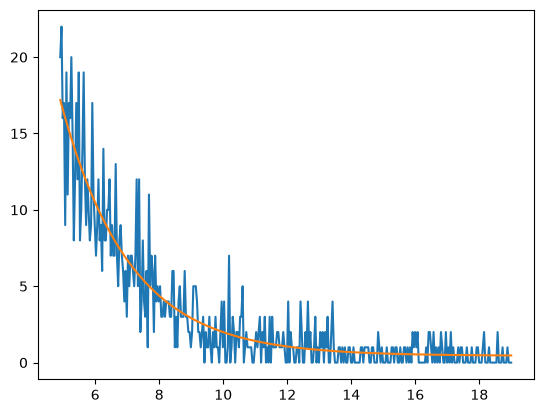

tau error: 0.13252593139384752
reduced chi squared: 1.0082694126920797


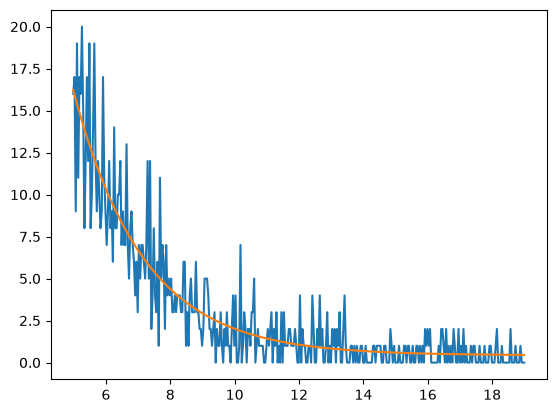

tau error: 0.13500202021491892
reduced chi squared: 1.0080962240456344


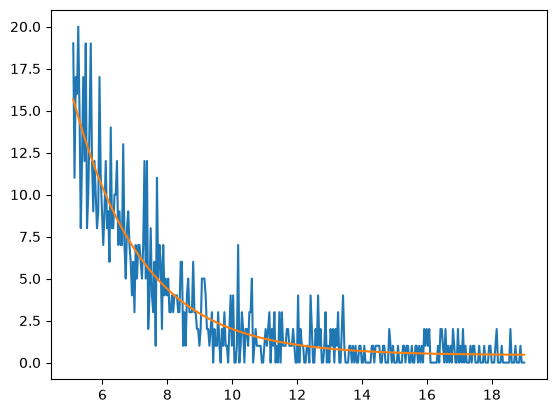

tau error: 0.14061266711845893
reduced chi squared: 1.0104369168523428


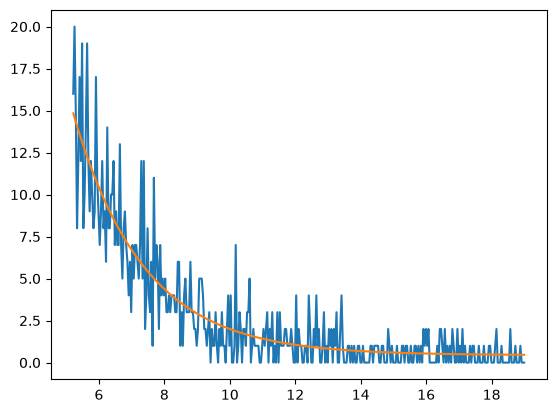

tau error: 0.14779833667860756
reduced chi squared: 1.010029021875011


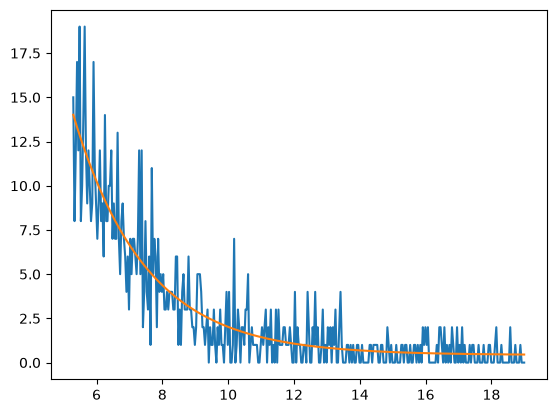

tau error: 0.14963661208781684
reduced chi squared: 1.0104099055910611


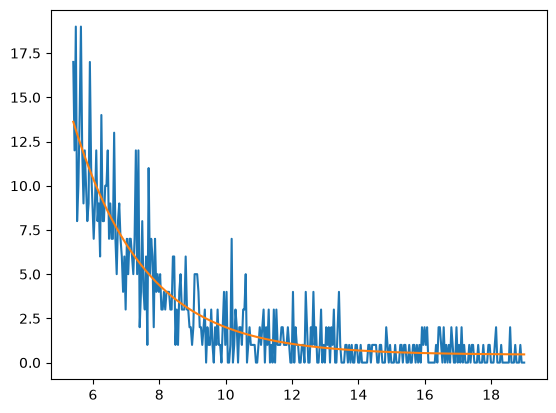

tau error: 0.15482797644097254
reduced chi squared: 1.0134072929239386


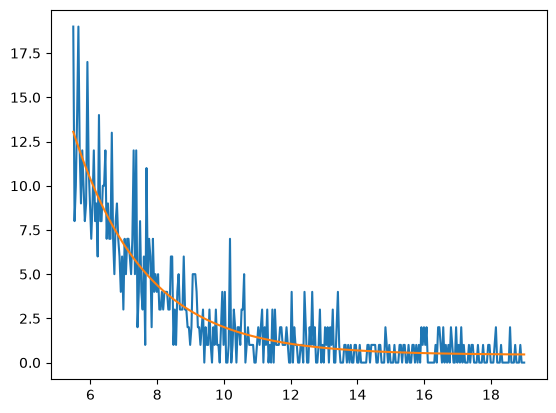

tau error: 0.1599412231162026
reduced chi squared: 1.0074228000819387


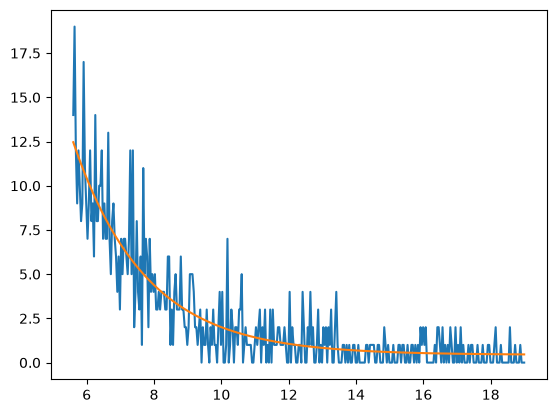

tau error: 0.17342238663697834
reduced chi squared: 1.0040078588441534


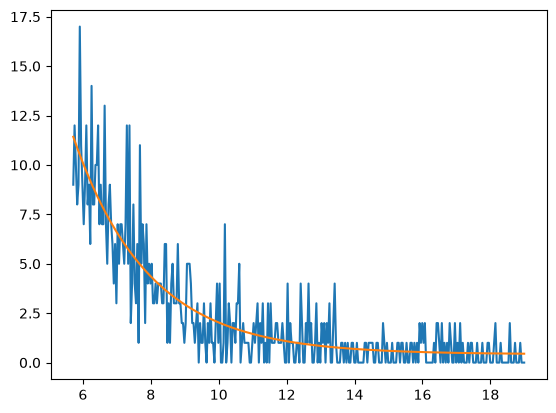

tau error: 0.17627689820432021
reduced chi squared: 1.008153288596457


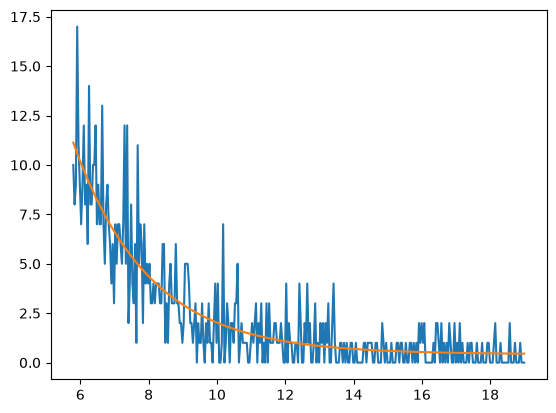

tau error: 0.1772682663882935
reduced chi squared: 1.0128377765435579


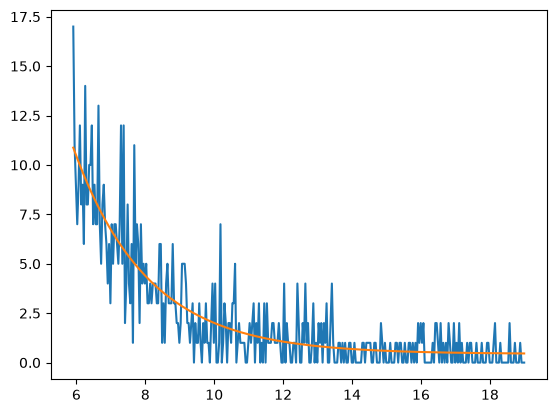

tau error: 0.18919892557662402
reduced chi squared: 1.0080613440813277


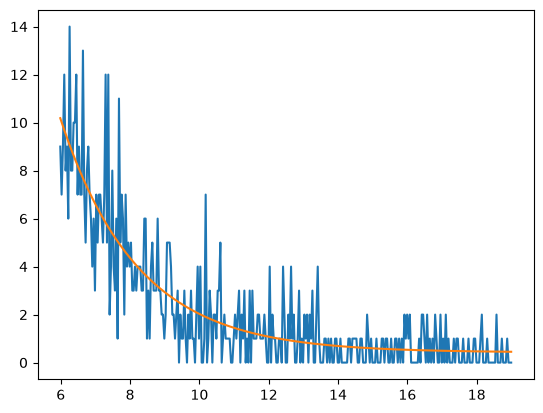

tau error: 0.19034116341271204
reduced chi squared: 1.0131724116469114


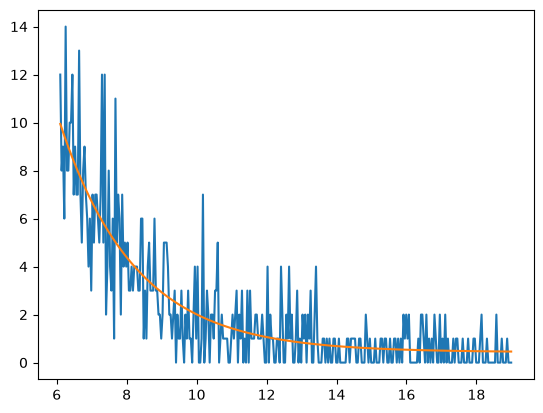

tau error: 0.197732610474784
reduced chi squared: 1.0199444928677752


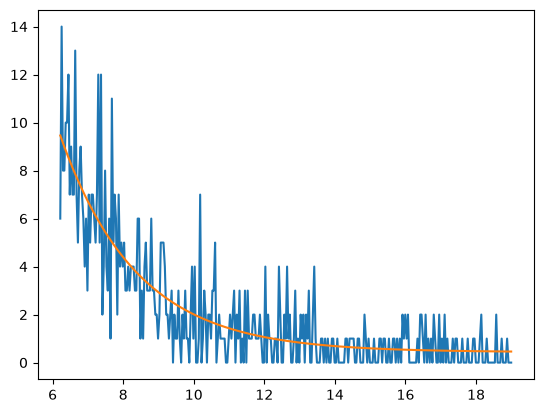

In [170]:
data_dict = get_data(data_path, TOTAL_CHANNELS)
time_cal_dict = get_data(time_cal_path_2, TOTAL_CHANNELS_2)


y_data = data_dict["data"]
y_data_rebinned = rebin_histogram(y_data, 512)

rebinned_data_dict = data_dict.copy()
rebinned_data_dict['data'] = y_data_rebinned


time_fit_param, step_array, binary_peaks = get_time_cal(rebinned_data_dict, time_cal_dict, period = 1.28, degree = 1)

m = time_fit_param[0]
b = time_fit_param[1]

start_times = np.round(np.arange(1.2, 7.01, 0.1), 2)            # fit start, time after the muon (us)
end_channel = get_channel_from_time_linear(19, time_fit_param)   # TAC time

taus, errs = [], []
for s in start_times:
    start_channel = get_channel_from_time_linear(s - T_DELAY_US, time_fit_param)   # muon time -> TAC channel
    fit_y_data, _, fit_tau, _, fit_tau_err = fit_exp_dist_w_oxy_Si(y_data_rebinned, start_channel,
                                                          end_channel, time_fit_param, m)
    taus.append(fit_tau)
    errs.append(fit_tau_err)

    x_data = np.arange(start_channel, end_channel + 1)
    x_time = get_time_from_channel_linear(x_data, time_fit_param)

    plt.plot(x_time, y_data_rebinned[start_channel: end_channel + 1])
    plt.plot(x_time, fit_y_data)
    plt.show()
taus, errs = np.array(taus), np.array(errs)

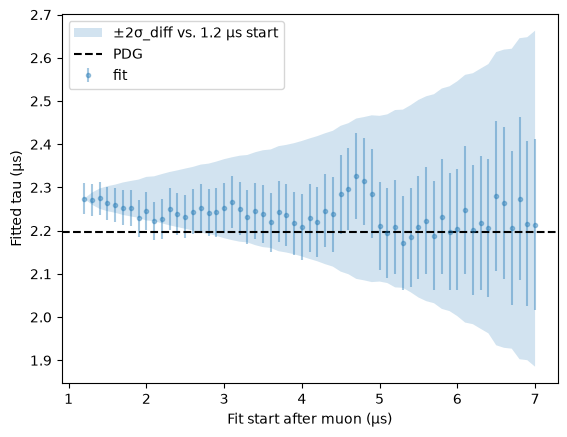

In [171]:
band = np.sqrt(np.clip(errs**2 - errs[0]**2, 0, None))   # expected scatter vs. the first start
plt.errorbar(start_times, taus, errs, fmt=".", alpha=0.4, label="fit")
plt.fill_between(start_times, taus[0] - 2*band, taus[0] + 2*band, alpha=0.2,
                 label=f"±2σ_diff vs. {start_times[0]} {mu}s start")
plt.axhline(2.1969811, color="k", ls="--", label="PDG")
plt.xlabel(f"Fit start after muon ({mu}s)")
plt.ylabel(f"Fitted tau ({mu}s)")
plt.legend()
plt.show()

# Combining data sets

In [172]:
# data_path_1 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest.Spe"
# data_path_2 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest2.Spe"
# data_path_3 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest3.Spe"

# data_paths = [data_path_1,data_path_2, data_path_3]

# all_data = None
# for path in data_paths:
#   # y_data = get_data(data_path, TOTAL_CHANNELS)["data"]
#   # y_data = np.array(y_data)

#   if all_data is None:
#     all_data = y_data
#   else:
#     all_data += y_data

# plt.plot(all_data)

# Hourly Counts

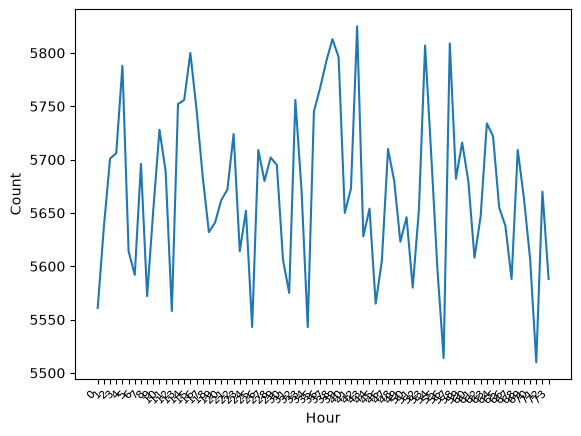

In [173]:
counts = []
timestamps = []
for file in sorted(os.listdir(hourly_folder_path)):
  if file.endswith(".Spe"):
    data_path = os.path.join(hourly_folder_path, file)
    muon_data_dict = get_data(data_path, TOTAL_CHANNELS)

    timestamp = f"{muon_data_dict['start_date']} {muon_data_dict['start_time']}"
    timestamps.append(timestamp)

    muon_data = muon_data_dict["data"]
    count = sum(muon_data)
    counts.append(count)

hours = [f"{i}" for i in range(len(counts))]

plt.plot(hours, counts)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.xlabel("Hour")
plt.ylabel("Count")
plt.show()

In [174]:
count_data = pd.DataFrame({"timestamp": timestamps, "count": counts})

#convert to datetime round to the nearest hour
count_data['timestamp'] = pd.to_datetime(count_data['timestamp'])
count_data['timestamp'] = count_data['timestamp'].dt.round('h')

met_data = pd.read_csv(r"C:\pyt\ADV-Lab\muon-lifetime\ATT.csv", parse_dates=["valid"])
met_columns = ['valid','tmpf','alti']
met_data = met_data[met_columns]

# round the valid column to the nearest hour
met_data['valid'] = met_data['valid'].dt.round('h')

merged = met_data.merge(count_data, how='inner', left_on='valid', right_on='timestamp').drop(columns = ['valid'])
merged

,tmpf,alti,timestamp,count
0,59.0,30.03,2026-11-13 01:00:00,5689
1,58.0,30.03,2026-11-13 02:00:00,5558
2,56.0,30.02,2026-11-13 03:00:00,5752
3,55.0,30.02,2026-11-13 04:00:00,5756
4,56.0,30.02,2026-11-13 05:00:00,5800
...,...,...,...,...
92,53.0,30.13,2026-11-15 12:00:00,5607
93,53.0,30.13,2026-11-15 13:00:00,5510
94,53.0,30.11,2026-11-15 14:00:00,5670
95,53.0,30.11,2026-11-15 14:00:00,5670


array([[<Axes: xlabel='timestamp'>],
       [<Axes: xlabel='timestamp'>],
       [<Axes: xlabel='timestamp'>]], dtype=object)

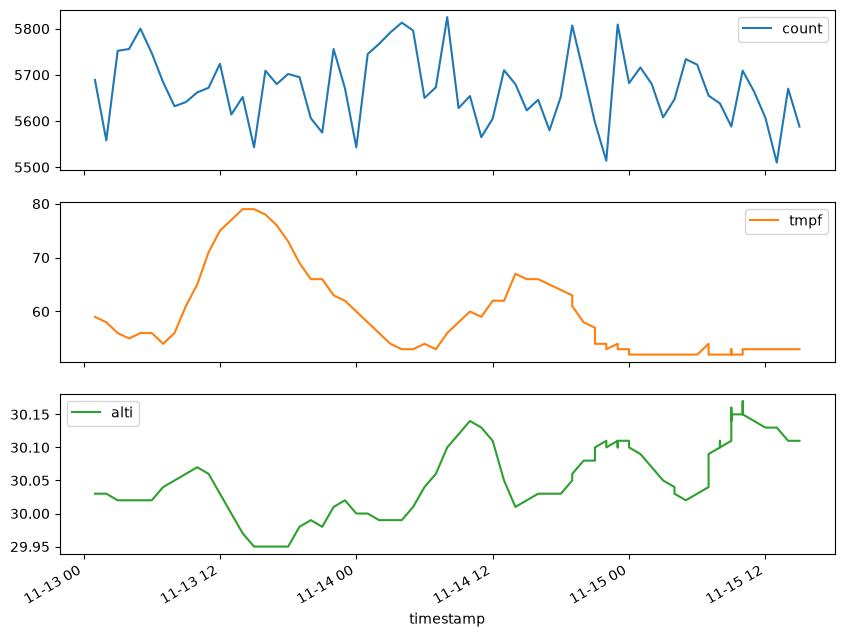

In [175]:
merged.plot(x='timestamp', y=['count', 'tmpf', 'alti'], subplots=True, layout=(3, 1), figsize=(10, 8))

In [176]:
import statsmodels.api as sm

# =============================================================================
# Barometric fit: Poisson log-link regression (GLM)
#
#   E[N_i] = t_i * exp( b0 + beta*(P_i - P_mean) [+ alpha*(T_i - T_mean)] )
#
#   N_i = counts in hourly window i,  t_i = length of window i (s)
#   log(t_i) is an "offset" (coefficient fixed at 1), so windows that are not
#   exactly 3600 s are handled exactly.
#   exp(b0) = rate (Hz) at the mean pressure
#   100*beta  = barometric coefficient (%/hPa)
#   100*alpha = temperature coefficient (%/degC), only if the temperature term is used
# =============================================================================

LAB_TZ = "America/Chicago"   # Maestro writes .Spe start times in the lab computer's local time
MET_TZ = "America/Chicago"   # time zone of the 'valid' column in the IEM CSV you downloaded
                             # (set to "UTC" if you picked UTC on the IEM download page)
                             
STATION_ELEV_M = 204.2       # Austin Camp Mabry elevation (NCEI)
INHG_TO_HPA = 33.8639


def altimeter_to_station_pressure(alti_hpa, elev_m=STATION_ELEV_M):
    """Invert the NWS altimeter-setting formula -> station pressure (hPa).
    Use this, not sea-level pressure (mslp), which mixes in temperature."""
    n = 0.190284
    return (alti_hpa**n - 8.4228807e-5 * elev_m) ** (1 / n) + 0.3


def load_met(paths, met_tz=MET_TZ):
    """Read one or more manually downloaded IEM ASOS CSVs (needs columns valid, tmpf, alti).
    Overlapping downloads are fine: duplicate times are dropped."""
    if isinstance(paths, str):
        paths = [paths]
    met = pd.concat([pd.read_csv(p, na_values=["M"]) for p in paths], ignore_index=True)

    t = pd.to_datetime(met["valid"])
    if t.dt.tz is None:
        t = t.dt.tz_localize(met_tz, ambiguous="NaT", nonexistent="shift_forward")
    met.index = pd.DatetimeIndex(t.dt.tz_convert("UTC"), name="time_utc")
    met = met[met.index.notna()]
    met = met[~met.index.duplicated(keep="last")].sort_index()

    out = pd.DataFrame(index=met.index)
    alti_hpa = pd.to_numeric(met["alti"], errors="coerce") * INHG_TO_HPA
    out["p_hPa"] = altimeter_to_station_pressure(alti_hpa)
    out["temp_C"] = (pd.to_numeric(met["tmpf"], errors="coerce") - 32) * 5 / 9
    return out


def load_hourly_counts(folder, total_channels=TOTAL_CHANNELS, lab_tz=LAB_TZ):
    """One row per .Spe file: start time (index, UTC), real/live time (s), total counts."""
    rows = []
    for f in sorted(os.listdir(folder)):
        if f.endswith(".Spe"):
            d = get_data(os.path.join(folder, f), total_channels)
            rows.append({"file": f,
                         "start_local": pd.to_datetime(f"{d['start_date']} {d['start_time']}",
                                                       format="%m/%d/%Y %H:%M:%S"),
                         "real_s": d["real_time"],
                         "live_s": d["live_time"],
                         "counts": int(np.sum(d["data"]))})
    df = pd.DataFrame(rows)
    df["start_local"] = df["start_local"].dt.tz_localize(lab_tz, ambiguous="NaT",
                                                         nonexistent="shift_forward")
    df.index = pd.DatetimeIndex(df["start_local"].dt.tz_convert("UTC"), name="start_utc")
    return df.sort_index()


def add_weather(df, met, time_col="real_s", max_gap_h=3):
    """Pressure and temperature at the MIDDLE of each counting window, linearly
    interpolated between METARs (= the hourly average for a smoothly varying field).
    Windows outside the weather data, or inside a gap > max_gap_h hours, get NaN."""
    mid = df.index + pd.to_timedelta(df[time_col].to_numpy() / 2, unit="s")
    out = df.copy()
    for col in ["p_hPa", "temp_C"]:
        s = met[col].dropna()
        x, m = s.index.asi8, mid.asi8
        val = np.interp(m, x, s.to_numpy())
        k = np.searchsorted(x, m)
        ok = (k > 0) & (k < len(x))
        gap_h = np.full(len(m), np.inf)
        gap_h[ok] = (x[k[ok]] - x[k[ok] - 1]) / 3.6e12
        val[~ok | (gap_h > max_gap_h)] = np.nan
        out[col] = val
    return out


def design_matrix(df, p_col="p_hPa", extra_cols=()):
    """Columns: constant, centered pressure, and any extra centered regressors."""
    X = pd.DataFrame({"const": 1.0, "dP": df[p_col] - df[p_col].mean()}, index=df.index)
    for c in extra_cols:
        X["d_" + c] = df[c] - df[c].mean()
    return X


def fit_glm(df, count_col="counts", time_col="real_s", p_col="p_hPa", extra_cols=()):
    """Poisson GLM, log link, offset log(window length). Returns (result, Pearson chi2/dof)."""
    X = design_matrix(df, p_col, extra_cols)
    model = sm.GLM(df[count_col], X, family=sm.families.Poisson(),
                   offset=np.log(df[time_col]))
    res = model.fit()
    chi2_dof = res.pearson_chi2 / res.df_resid
    return res, chi2_dof


def report(df, res, chi2_dof, count_col="counts", time_col="real_s", p_col="p_hPa"):
    b, e = res.params, res.bse
    # if chi2/dof > 1 there is extra (non-Poisson) scatter: inflate the errors by sqrt(chi2/dof)
    es = e * np.sqrt(max(1.0, chi2_dof))
    rate = df[count_col] / df[time_col]
    t_loc = df.index.tz_convert(LAB_TZ)

    print(f"windows used      : {len(df)}   ({t_loc.min():%m/%d %H:%M} to {t_loc.max():%m/%d %H:%M} local)")
    print(f"pressure range    : {df[p_col].min():.1f} - {df[p_col].max():.1f} hPa   (sd {df[p_col].std():.2f} hPa)")
    print(f"rate at mean P    : {np.exp(b['const']):.4f} Hz")
    print(f"beta (pressure)   : {100*b['dP']:+.4f} ± {100*e['dP']:.4f} %/hPa"
          f"   [chi2-scaled: ± {100*es['dP']:.4f}]")
    for name in b.index[2:]:
        unit = "%/degC" if "temp" in name else "%/unit"
        print(f"{name + ' coef':18s}: {100*b[name]:+.4f} ± {100*e[name]:.4f} {unit}"
              f"   [chi2-scaled: ± {100*es[name]:.4f}]")
        cov = res.cov_params()
        r = cov.loc["dP", name] / np.sqrt(cov.loc["dP", "dP"] * cov.loc[name, name])
        print(f"{'corr(beta, ' + name + ')':18s}: {r:+.2f}   (near ±1 = pressure and temp can't be separated yet)")
    print(f"Pearson chi2/dof  : {chi2_dof:.3f}   (dof = {int(res.df_resid)}; ~1 = pure counting noise)")
    print(f"r(rate, pressure) : {np.corrcoef(rate, df[p_col])[0, 1]:+.3f}   (descriptive only; beta is the result)")


def plot_fit(df, res, count_col="counts", time_col="real_s", p_col="p_hPa"):
    b = res.params
    rate = df[count_col] / df[time_col]
    err = np.sqrt(df[count_col]) / df[time_col]
    mu = res.fittedvalues
    pull = (df[count_col] - mu) / np.sqrt(mu)
    t_loc = df.index.tz_convert(LAB_TZ).tz_localize(None)

    # remove the fitted effect of any extra regressors so the top panel shows pressure alone
    extra_names = list(b.index[2:])
    if extra_names:
        X = design_matrix(df, p_col, [c[2:] for c in extra_names])
        corr = np.exp(-(X[extra_names] @ b[extra_names]))
    else:
        corr = 1.0

    fig, ax = plt.subplots(3, 1, figsize=(8, 11))

    ax[0].errorbar(df[p_col], rate * corr, err * corr, fmt="o", ms=3, alpha=0.5,
                   label="data" + (" (corrected to mean temp)" if extra_names else ""))
    pp = np.linspace(df[p_col].min(), df[p_col].max(), 100)
    ax[0].plot(pp, np.exp(b["const"] + b["dP"] * (pp - df[p_col].mean())), "r-",
               label=f"fit: beta = {100*b['dP']:+.3f} %/hPa")
    ax[0].set(xlabel="Station pressure (hPa)", ylabel="Rate (Hz)")
    ax[0].legend()

    ax[1].errorbar(t_loc, rate, err, fmt=".", alpha=0.4, label="rate")
    ax[1].plot(t_loc, mu / df[time_col], "r-", lw=1, label="fit")
    ax[1].set_ylabel("Rate (Hz)")
    ax[1].legend(loc="upper left")
    axp = ax[1].twinx()
    axp.plot(t_loc, df[p_col], "g-", lw=1)
    axp.set_ylabel("Station pressure (hPa)", color="g")

    ax[2].plot(t_loc, pull, ".")
    ax[2].axhline(0, color="k", lw=0.8)
    ax[2].set(xlabel=f"Window start ({LAB_TZ})", ylabel="Residual (sigma)")

    for a in ax[1:]:
        a.tick_params(axis="x", labelrotation=30)
    fig.tight_layout()
    plt.show()

62 of 74 hourly windows matched to Camp Mabry weather

windows used      : 62   (11/13 00:31 to 11/15 13:31 local)
pressure range    : 990.2 - 997.1 hPa   (sd 1.78 hPa)
rate at mean P    : 1.5758 Hz
beta (pressure)   : -0.3272 ± 0.1183 %/hPa   [chi2-scaled: ± 0.1183]
d_temp_C coef     : -0.1280 ± 0.0480 %/degC   [chi2-scaled: ± 0.0480]
corr(beta, d_temp_C): +0.59   (near ±1 = pressure and temp can't be separated yet)
Pearson chi2/dof  : 0.908   (dof = 59; ~1 = pure counting noise)
r(rate, pressure) : -0.186   (descriptive only; beta is the result)

pressure-only beta: -0.1407 ± 0.0954 %/hPa
temp term: deviance drop = 7.12, p = 0.008   (p < 0.05 -> temperature term is supported by the data)


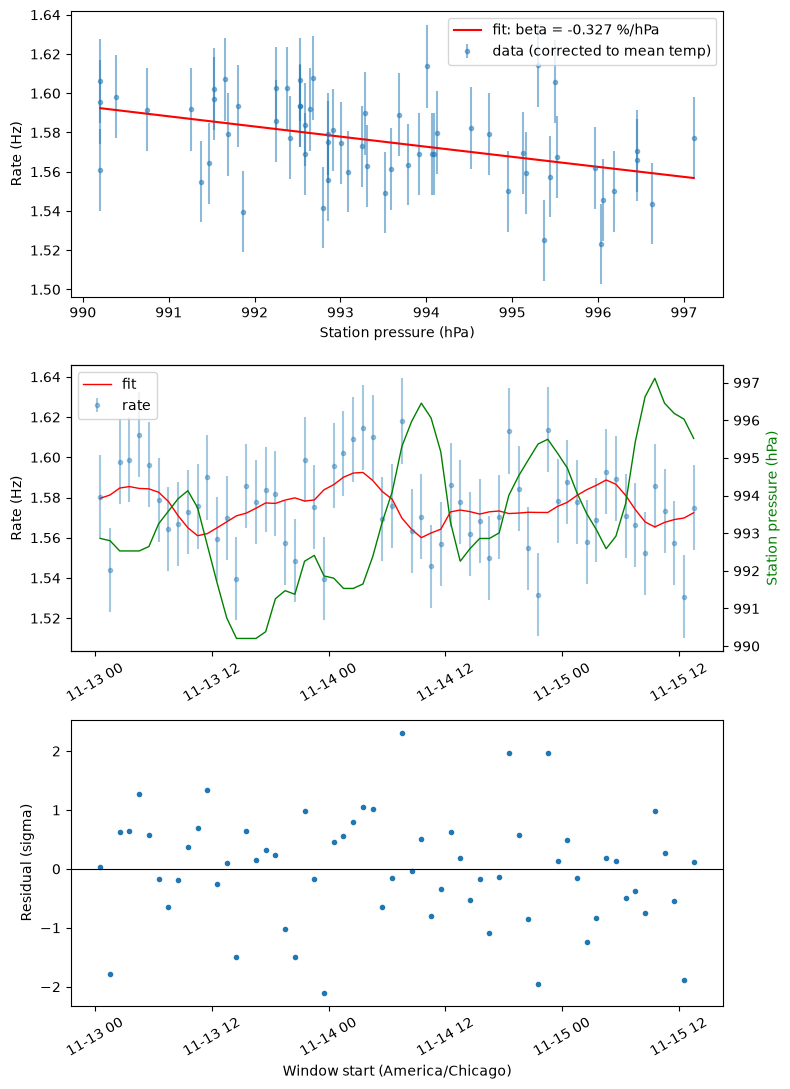

In [177]:
# ---------------- inputs ----------------
# IEM ASOS CSVs for station ATT (columns valid, tmpf, alti). Add each new manual
# download to this list; overlapping time ranges are fine.
MET_CSV_PATHS = [r"C:\pyt\ADV-Lab\muon-lifetime\ATT.csv"]

USE_TEMP = True      # True -> add surface temperature (degC) as a second regressor
TIME_COL = "real_s"   # exposure per window; "live_s" uses MCA live time instead

# ---------------- one row per hourly .Spe file, with weather at mid-window ----------------
met = load_met(MET_CSV_PATHS)
df = add_weather(load_hourly_counts(hourly_folder_path), met, time_col=TIME_COL)

n_all = len(df)
need = ["p_hPa"] + (["temp_C"] if USE_TEMP else [])
df = df.dropna(subset=need)
df = df[df[TIME_COL] > 0]
print(f"{len(df)} of {n_all} hourly windows matched to Camp Mabry weather\n")

# ---------------- fit ----------------
extra = ["temp_C"] if USE_TEMP else []
res, chi2_dof = fit_glm(df, time_col=TIME_COL, extra_cols=extra)
report(df, res, chi2_dof, time_col=TIME_COL)

if USE_TEMP:
    # does the temperature term improve the fit? likelihood-ratio test vs. pressure only
    from scipy.stats import chi2 as chi2_dist
    res_p, _ = fit_glm(df, time_col=TIME_COL)
    d_dev = res_p.deviance - res.deviance
    print(f"\npressure-only beta: {100*res_p.params['dP']:+.4f} ± {100*res_p.bse['dP']:.4f} %/hPa")
    print(f"temp term: deviance drop = {d_dev:.2f}, p = {chi2_dist.sf(d_dev, 1):.3f}"
          "   (p < 0.05 -> temperature term is supported by the data)")

plot_fit(df, res, time_col=TIME_COL)